In [351]:
import pandas as pd

# Load raw dataset
df = pd.read_csv("../data/hotel_bookings.csv")

# Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Handle missing values
df["children"] = df["children"].fillna(0)
df["country"] = df["country"].astype("object").fillna("Unknown")
df["agent"] = df["agent"].astype("object").fillna("No Agent")
df["company"] = df["company"].astype("object").fillna("No Company")

# Create analytical columns
df["total_guests"] = (
    df["adults"] + df["children"] + df["babies"]
).astype(int)
df["total_nights"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)
df["booking_status"] = df["is_canceled"].map({
    0: "Not Canceled",
    1: "Canceled"
})
df["estimated_revenue"] = df["adr"] * df["total_nights"]

# Save cleaned dataset
df.to_csv("../data/cleaned_hotel_bookings.csv", index=False)

print("Cleaned dataset exported successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Cleaned dataset exported successfully!
Rows: 87396
Columns: 36


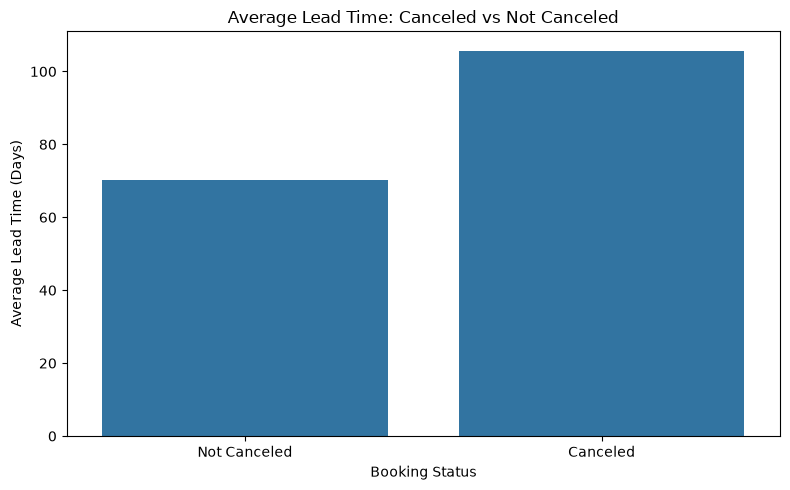

In [352]:
# Create lead-time analysis again
lead_time_analysis = (
    df.groupby("is_canceled")
      .agg(
          bookings=("is_canceled", "size"),
          average_lead_time=("lead_time", "mean")
      )
      .reset_index()
)

lead_time_analysis["booking_status"] = lead_time_analysis["is_canceled"].map({
    0: "Not Canceled",
    1: "Canceled"
})

# Create chart
plt.figure(figsize=(8, 5))

sns.barplot(
    data=lead_time_analysis,
    x="booking_status",
    y="average_lead_time"
)

plt.title("Average Lead Time: Canceled vs Not Canceled")
plt.xlabel("Booking Status")
plt.ylabel("Average Lead Time (Days)")
plt.tight_layout()

plt.show()

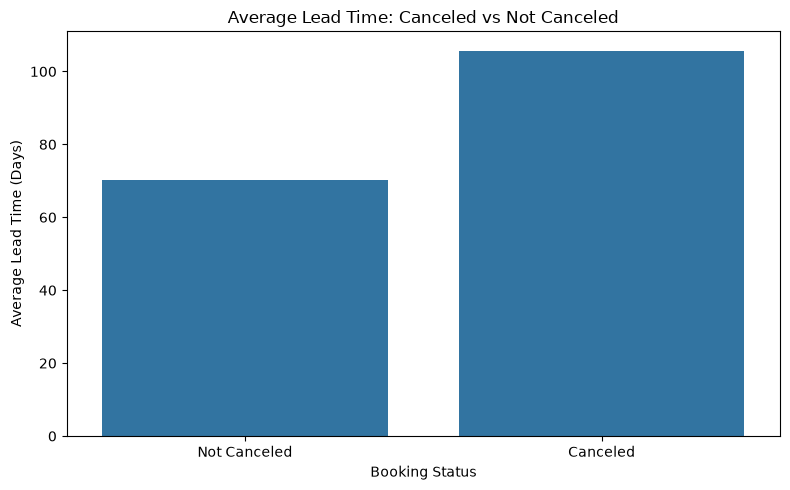

In [353]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=lead_time_analysis,
    x="booking_status",
    y="average_lead_time"
)

plt.title("Average Lead Time: Canceled vs Not Canceled")
plt.xlabel("Booking Status")
plt.ylabel("Average Lead Time (Days)")
plt.tight_layout()

plt.show()

In [354]:
# Lead time analysis
lead_time_analysis = (
    df.groupby("is_canceled")
      .agg(
          bookings=("is_canceled", "size"),
          average_lead_time=("lead_time", "mean"),
          median_lead_time=("lead_time", "median")
      )
      .reset_index()
)

lead_time_analysis["booking_status"] = lead_time_analysis["is_canceled"].map({
    0: "Not Canceled",
    1: "Canceled"
})

lead_time_analysis["average_lead_time"] = (
    lead_time_analysis["average_lead_time"].round(2)
)

print(
    lead_time_analysis[
        [
            "booking_status",
            "bookings",
            "average_lead_time",
            "median_lead_time"
        ]
    ].to_string(index=False)
)

booking_status  bookings  average_lead_time  median_lead_time
  Not Canceled     63371              70.10              38.0
      Canceled     24025             105.72              80.0


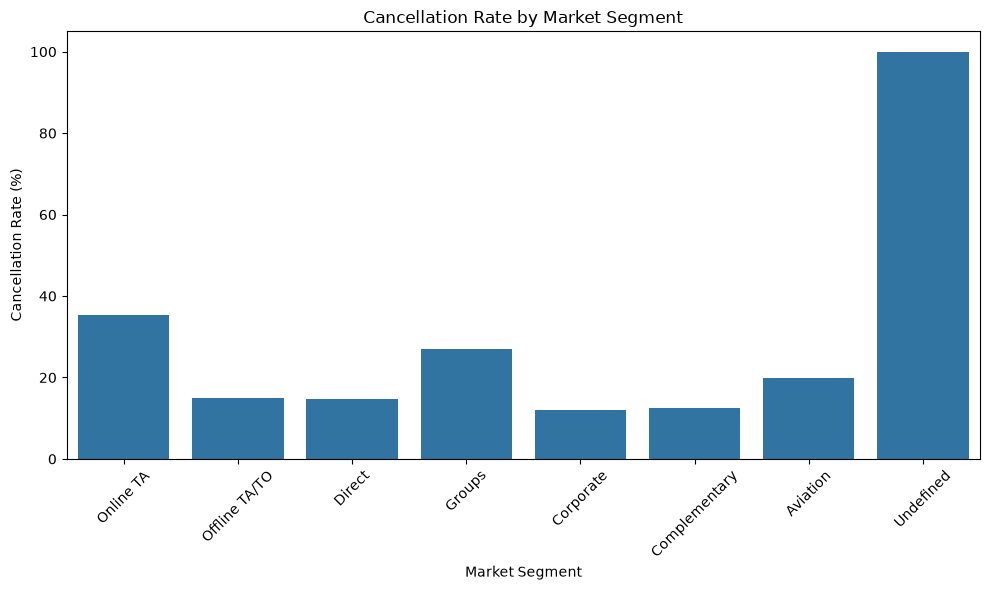

In [355]:
# Market segment cancellation analysis
segment_analysis = (
    df.groupby("market_segment")
      .agg(
          bookings=("market_segment", "size"),
          canceled_bookings=("is_canceled", "sum"),
          cancellation_rate=("is_canceled", "mean"),
          average_adr=("adr", "mean")
      )
      .reset_index()
      .sort_values("bookings", ascending=False)
)

segment_analysis["cancellation_rate"] *= 100

# Create chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_analysis,
    x="market_segment",
    y="cancellation_rate"
)

plt.title("Cancellation Rate by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

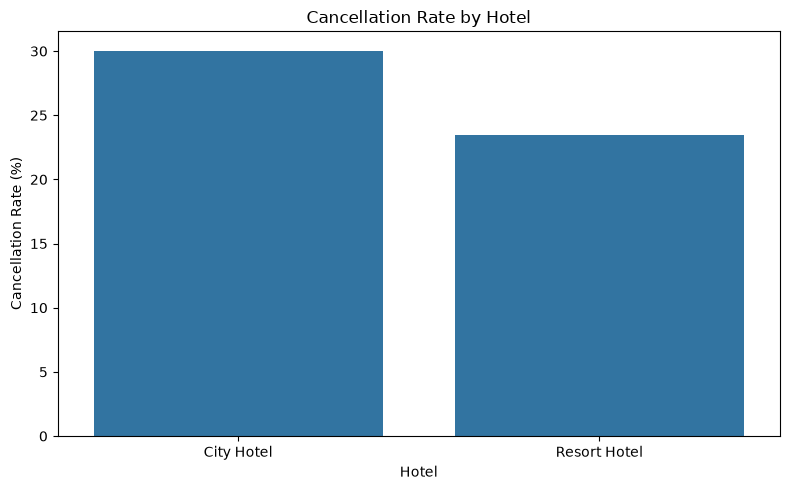

In [356]:
# Cancellation analysis by hotel
cancellation_by_hotel = (
    df.groupby("hotel")
      .agg(
          bookings=("hotel", "size"),
          canceled_bookings=("is_canceled", "sum"),
          cancellation_rate=("is_canceled", "mean")
      )
      .reset_index()
)

cancellation_by_hotel["cancellation_rate"] *= 100

# Create chart
plt.figure(figsize=(8, 5))

sns.barplot(
    data=cancellation_by_hotel,
    x="hotel",
    y="cancellation_rate"
)

plt.title("Cancellation Rate by Hotel")
plt.xlabel("Hotel")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()

plt.show()

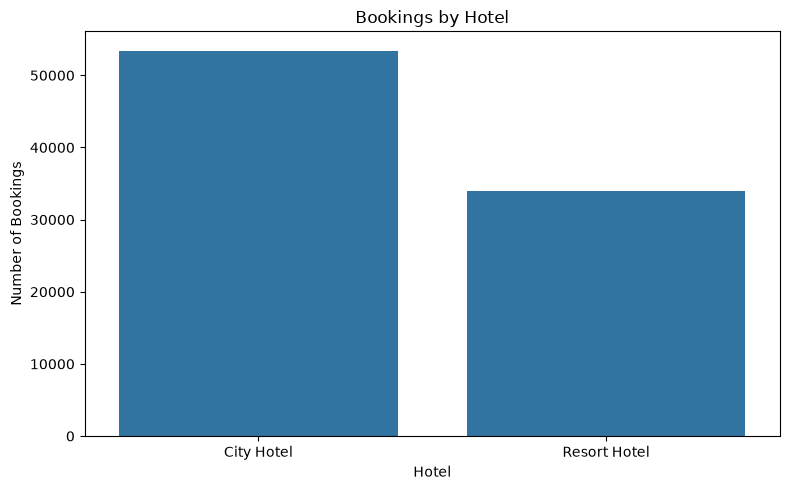

In [357]:
# Reload and prepare the data
df = pd.read_csv("../data/hotel_bookings.csv")

# Remove duplicates
df = df.drop_duplicates().reset_index(drop=True)

# Create required metric
df["total_nights"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)

df["estimated_revenue"] = (
    df["adr"] * df["total_nights"]
)

# Hotel performance
hotel_analysis = (
    df.groupby("hotel")
      .agg(
          bookings=("hotel", "size"),
          cancellation_rate=("is_canceled", "mean"),
          average_adr=("adr", "mean"),
          estimated_revenue=("estimated_revenue", "sum")
      )
      .reset_index()
)

hotel_analysis["cancellation_rate"] *= 100

# Create chart
plt.figure(figsize=(8, 5))

sns.barplot(
    data=hotel_analysis,
    x="hotel",
    y="bookings"
)

plt.title("Bookings by Hotel")
plt.xlabel("Hotel")
plt.ylabel("Number of Bookings")
plt.tight_layout()

plt.show()

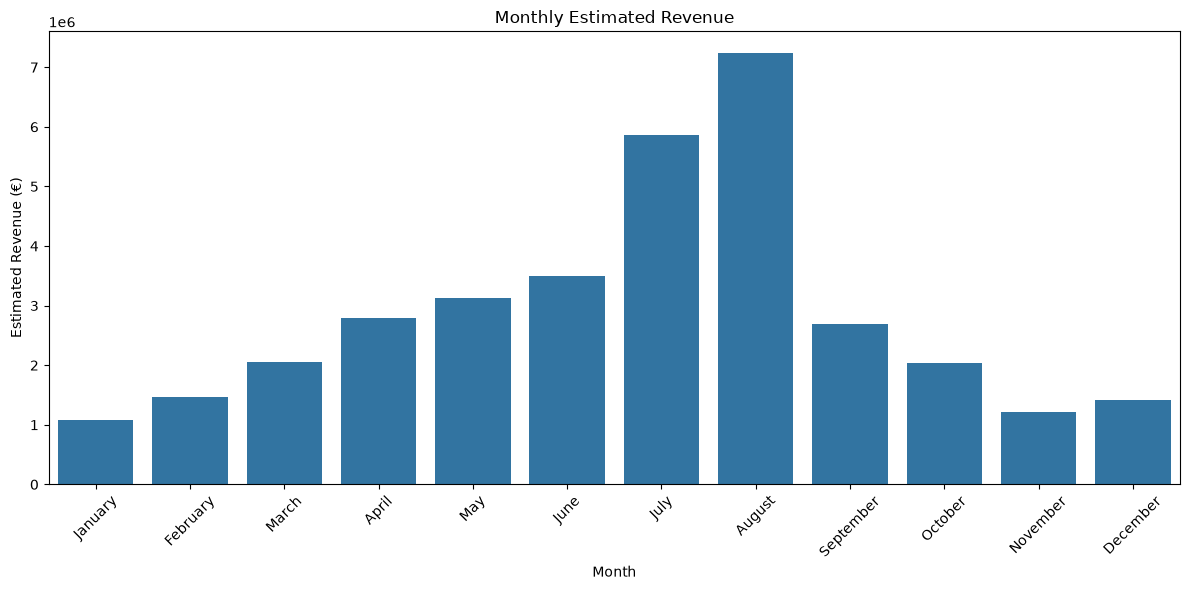

In [358]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=monthly_revenue,
    x="arrival_date_month",
    y="estimated_revenue"
)

plt.title("Monthly Estimated Revenue")
plt.xlabel("Month")
plt.ylabel("Estimated Revenue (€)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [359]:
# Reload and prepare data
df = pd.read_csv("../data/hotel_bookings.csv")

df = df.drop_duplicates().reset_index(drop=True)

df["total_nights"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)

df["estimated_revenue"] = df["adr"] * df["total_nights"]

# Correct month ordering
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_revenue = (
    df.groupby("arrival_date_month")
      .agg(
          bookings=("hotel", "size"),
          estimated_revenue=("estimated_revenue", "sum"),
          average_adr=("adr", "mean")
      )
      .reindex(month_order)
      .reset_index()
)

monthly_revenue["estimated_revenue"] = (
    monthly_revenue["estimated_revenue"].round(2)
)

monthly_revenue["average_adr"] = (
    monthly_revenue["average_adr"].round(2)
)

print(monthly_revenue.to_string(index=False))

arrival_date_month  bookings  estimated_revenue  average_adr
           January      4693         1079597.52        70.05
          February      6098         1473600.20        74.69
             March      7513         2048685.33        81.61
             April      7908         2787157.05       103.61
               May      8355         3123058.22       111.20
              June      7765         3496345.05       119.75
              July     10057         5863024.99       135.54
            August     11257         7240652.99       150.88
         September      6690         2689186.19       112.08
           October      6934         2032649.25        90.15
          November      4995         1219278.35        72.75
          December      5131         1407704.17        81.45


In [360]:
# Reload and prepare the data
df = pd.read_csv("../data/hotel_bookings.csv")

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Create total nights
df["total_nights"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)

# Repeat guest analysis
repeat_analysis = (
    df.groupby("is_repeated_guest")
      .agg(
          bookings=("is_repeated_guest", "size"),
          canceled_bookings=("is_canceled", "sum"),
          cancellation_rate=("is_canceled", "mean"),
          average_adr=("adr", "mean"),
          average_stay=("total_nights", "mean")
      )
      .reset_index()
)

# Create readable guest type
repeat_analysis["guest_type"] = repeat_analysis["is_repeated_guest"].map({
    0: "First-time Guest",
    1: "Repeat Guest"
})

# Convert cancellation rate to percentage
repeat_analysis["cancellation_rate"] = (
    repeat_analysis["cancellation_rate"] * 100
).round(2)

repeat_analysis["average_adr"] = repeat_analysis["average_adr"].round(2)
repeat_analysis["average_stay"] = repeat_analysis["average_stay"].round(2)

# Display results
print(
    repeat_analysis[
        [
            "guest_type",
            "bookings",
            "canceled_bookings",
            "cancellation_rate",
            "average_adr",
            "average_stay"
        ]
    ].to_string(index=False)
)

      guest_type  bookings  canceled_bookings  cancellation_rate  average_adr  average_stay
First-time Guest     83981              23764              28.30       108.04          3.70
    Repeat Guest      3415                261               7.64        64.59          1.93


In [361]:
top_countries = (
    df.groupby("country")
      .size()
      .reset_index(name="bookings")
      .sort_values("bookings", ascending=False)
      .head(10)
)

print(top_countries.to_string(index=False))

country  bookings
    PRT     27453
    GBR     10433
    FRA      8837
    ESP      7252
    DEU      5387
    ITA      3066
    IRL      3016
    BEL      2081
    BRA      1995
    NLD      1911


In [362]:
market_analysis = (
    df.groupby("market_segment")
      .agg(
          bookings=("market_segment", "size"),
          canceled_bookings=("is_canceled", "sum"),
          cancellation_rate=("is_canceled", "mean"),
          average_adr=("adr", "mean")
      )
      .reset_index()
)

market_analysis["cancellation_rate"] = (
    market_analysis["cancellation_rate"] * 100
).round(2)

market_analysis["average_adr"] = (
    market_analysis["average_adr"].round(2)
)

market_analysis = market_analysis.sort_values(
    "bookings",
    ascending=False
)

print(market_analysis.to_string(index=False))

market_segment  bookings  canceled_bookings  cancellation_rate  average_adr
     Online TA     51618              18245              35.35       118.17
 Offline TA/TO     13889               2063              14.85        81.76
        Direct     11804               1737              14.72       116.58
        Groups      4942               1335              27.01        74.86
     Corporate      4212                510              12.11        68.15
 Complementary       702                 88              12.54         3.05
      Aviation       227                 45              19.82       100.17
     Undefined         2                  2             100.00        15.00


In [363]:
customer_cancellation = (
    df.groupby("customer_type")
      .agg(
          bookings=("customer_type", "size"),
          canceled_bookings=("is_canceled", "sum"),
          cancellation_rate=("is_canceled", "mean")
      )
      .reset_index()
)

customer_cancellation["cancellation_rate"] = (
    customer_cancellation["cancellation_rate"] * 100
).round(2)

print(customer_cancellation.to_string(index=False))

  customer_type  bookings  canceled_bookings  cancellation_rate
       Contract      3139                512              16.31
          Group       544                 54               9.93
      Transient     71986              21672              30.11
Transient-Party     11727               1787              15.24


In [364]:
lead_time_analysis = (
    df.groupby("is_canceled")
      .agg(
          bookings=("is_canceled", "size"),
          average_lead_time=("lead_time", "mean"),
          median_lead_time=("lead_time", "median")
      )
      .reset_index()
)

lead_time_analysis["status"] = lead_time_analysis["is_canceled"].map({
    0: "Not Canceled",
    1: "Canceled"
})

lead_time_analysis["average_lead_time"] = (
    lead_time_analysis["average_lead_time"].round(2)
)

print(
    lead_time_analysis[
        ["status", "bookings", "average_lead_time", "median_lead_time"]
    ].to_string(index=False)
)

      status  bookings  average_lead_time  median_lead_time
Not Canceled     63371              70.10              38.0
    Canceled     24025             105.72              80.0


In [365]:
lead_time_analysis = (
    df.groupby("booking_status")
      .agg(
          bookings=("booking_status", "size"),
          average_lead_time=("lead_time", "mean"),
          median_lead_time=("lead_time", "median")
      )
      .reset_index()
)

lead_time_analysis["average_lead_time"] = (
    lead_time_analysis["average_lead_time"].round(2)
)

print(lead_time_analysis.to_string(index=False))

KeyError: 'booking_status'

In [ ]:
cancellation_by_hotel = (
    df.groupby("hotel")
      .agg(
          total_bookings=("hotel", "size"),
          canceled_bookings=("is_canceled", "sum"),
          cancellation_rate=("is_canceled", "mean")
      )
      .reset_index()
)

cancellation_by_hotel["cancellation_rate"] = (
    cancellation_by_hotel["cancellation_rate"] * 100
).round(2)

print(cancellation_by_hotel.to_string(index=False))

       hotel  total_bookings  canceled_bookings  cancellation_rate
  City Hotel           53428              16049              30.04
Resort Hotel           33968               7976              23.48


In [ ]:
monthly_bookings = (
    df.groupby("arrival_date_month")
      .size()
      .reset_index(name="bookings")
)

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_bookings["month"] = pd.Categorical(
    monthly_bookings["arrival_date_month"],
    categories=month_order,
    ordered=True
)

monthly_bookings = (
    monthly_bookings
    .sort_values("month")
    .drop(columns="month")
)

print(monthly_bookings.to_string(index=False))

arrival_date_month  bookings
           January      4693
          February      6098
             March      7513
             April      7908
               May      8355
              June      7765
              July     10057
            August     11257
         September      6690
           October      6934
          November      4995
          December      5131


In [ ]:
hotel_performance = (
    df.groupby("hotel")
      .agg(
          bookings=("hotel", "size"),
          cancellation_rate=("is_canceled", "mean"),
          average_adr=("adr", "mean"),
          average_stay=("total_nights", "mean"),
          estimated_revenue=("estimated_revenue", "sum")
      )
      .reset_index()
)

hotel_performance["cancellation_rate"] *= 100

hotel_performance["cancellation_rate"] = (
    hotel_performance["cancellation_rate"].round(2)
)

hotel_performance["average_adr"] = (
    hotel_performance["average_adr"].round(2)
)

hotel_performance["average_stay"] = (
    hotel_performance["average_stay"].round(2)
)

hotel_performance["estimated_revenue"] = (
    hotel_performance["estimated_revenue"].round(2)
)

print(hotel_performance.to_string(index=False))

       hotel  bookings  cancellation_rate  average_adr  average_stay  estimated_revenue
  City Hotel     53428              30.04       110.99          3.15        18774101.54
Resort Hotel     33968              23.48        99.03          4.39        15686837.77


In [ ]:
import pandas as pd

# Load original dataset
df = pd.read_csv("../data/hotel_bookings.csv")

# Remove duplicates
df = df.drop_duplicates().reset_index(drop=True)

# Handle missing values
df["children"] = df["children"].fillna(0)
df["country"] = df["country"].astype("object").fillna("Unknown")
df["agent"] = df["agent"].astype("object").fillna("No Agent")
df["company"] = df["company"].astype("object").fillna("No Company")

# Create business metrics
df["total_guests"] = (
    df["adults"] +
    df["children"] +
    df["babies"]
)

df["total_nights"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)

df["booking_status"] = df["is_canceled"].map({
    0: "Not Canceled",
    1: "Canceled"
})

df["estimated_revenue"] = (
    df["adr"] * df["total_nights"]
)

# Calculate KPIs
total_bookings = len(df)
cancellation_rate = df["is_canceled"].mean() * 100
avg_daily_rate = df["adr"].mean()
avg_stay = df["total_nights"].mean()
total_estimated_revenue = df["estimated_revenue"].sum()

print("HOTEL BOOKING KPI SUMMARY")
print("=" * 50)
print(f"Total Bookings: {total_bookings:,}")
print(f"Cancellation Rate: {cancellation_rate:.2f}%")
print(f"Average Daily Rate: €{avg_daily_rate:.2f}")
print(f"Average Stay: {avg_stay:.2f} nights")
print(f"Estimated Revenue: €{total_estimated_revenue:,.2f}")

HOTEL BOOKING KPI SUMMARY
Total Bookings: 87,396
Cancellation Rate: 27.49%
Average Daily Rate: €106.34
Average Stay: 3.63 nights
Estimated Revenue: €34,460,939.31


In [ ]:
print("HOTEL BOOKING KPI SUMMARY")
print("=" * 50)

total_bookings = len(df)
cancellation_rate = df["is_canceled"].mean() * 100
avg_daily_rate = df["adr"].mean()
avg_stay = df["total_nights"].mean()
total_estimated_revenue = df["estimated_revenue"].sum()

print(f"Total Bookings: {total_bookings:,}")
print(f"Cancellation Rate: {cancellation_rate:.2f}%")
print(f"Average Daily Rate: €{avg_daily_rate:.2f}")
print(f"Average Stay: {avg_stay:.2f} nights")
print(f"Estimated Revenue: €{total_estimated_revenue:,.2f}")

HOTEL BOOKING KPI SUMMARY
Total Bookings: 87,396
Cancellation Rate: 27.49%
Average Daily Rate: €106.34
Average Stay: 3.63 nights
Estimated Revenue: €34,460,939.31


In [ ]:
# 1. Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# 2. Handle missing values
df["children"] = df["children"].fillna(0)
df["country"] = df["country"].astype("object").fillna("Unknown")
df["agent"] = df["agent"].astype("object").fillna("No Agent")
df["company"] = df["company"].astype("object").fillna("No Company")

# 3. Create business metrics
df["total_guests"] = (
    df["adults"] +
    df["children"] +
    df["babies"]
)

df["total_nights"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)

df["booking_status"] = df["is_canceled"].map({
    0: "Not Canceled",
    1: "Canceled"
})

df["estimated_revenue"] = (
    df["adr"] * df["total_nights"]
)

# 4. Verify
print("Rows:", len(df))
print("Duplicates:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())
print("New columns:", [
    "total_guests",
    "total_nights",
    "booking_status",
    "estimated_revenue"
])

Rows: 87396
Duplicates: 0
Missing values: 0
New columns: ['total_guests', 'total_nights', 'booking_status', 'estimated_revenue']


In [ ]:
print("HOTEL BOOKING OVERVIEW")
print("=" * 50)

print("Total unique bookings:", len(df))

print("\nBookings by hotel:")
print(df["hotel"].value_counts())

print("\nBooking status:")
print(df["booking_status"].value_counts())

print("\nOverall cancellation rate:",
      round(df["is_canceled"].mean() * 100, 2), "%")

HOTEL BOOKING OVERVIEW
Total unique bookings: 87396

Bookings by hotel:
hotel
City Hotel      53428
Resort Hotel    33968
Name: count, dtype: int64

Booking status:
booking_status
Not Canceled    63371
Canceled        24025
Name: count, dtype: int64

Overall cancellation rate: 27.49 %


In [ ]:
# Create business metrics

df["total_guests"] = df["adults"] + df["children"] + df["babies"]

df["total_nights"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)

df["booking_status"] = df["is_canceled"].map({
    0: "Not Canceled",
    1: "Canceled"
})

df["estimated_revenue"] = df["adr"] * df["total_nights"]


# Verify immediately
print("New columns:")
print([
    "total_guests",
    "total_nights",
    "booking_status",
    "estimated_revenue"
])

print("\nSample data:")
print(
    df[
        [
            "hotel",
            "total_guests",
            "total_nights",
            "booking_status",
            "adr",
            "estimated_revenue"
        ]
    ].head(10)
)

New columns:
['total_guests', 'total_nights', 'booking_status', 'estimated_revenue']

Sample data:
          hotel  total_guests  total_nights booking_status    adr  \
0  Resort Hotel           2.0             0   Not Canceled    0.0   
1  Resort Hotel           2.0             0   Not Canceled    0.0   
2  Resort Hotel           1.0             1   Not Canceled   75.0   
3  Resort Hotel           1.0             1   Not Canceled   75.0   
4  Resort Hotel           2.0             2   Not Canceled   98.0   
5  Resort Hotel           2.0             2   Not Canceled  107.0   
6  Resort Hotel           2.0             2   Not Canceled  103.0   
7  Resort Hotel           2.0             3       Canceled   82.0   
8  Resort Hotel           2.0             3       Canceled  105.5   
9  Resort Hotel           2.0             4       Canceled  123.0   

   estimated_revenue  
0                0.0  
1                0.0  
2               75.0  
3               75.0  
4              196.0  
5  

In [ ]:
print(
    df[
        [
            "hotel",
            "total_guests",
            "total_nights",
            "booking_status",
            "adr",
            "estimated_revenue"
        ]
    ].head(10)
)

          hotel  total_guests  total_nights booking_status    adr  \
0  Resort Hotel           2.0             0   Not Canceled    0.0   
1  Resort Hotel           2.0             0   Not Canceled    0.0   
2  Resort Hotel           1.0             1   Not Canceled   75.0   
3  Resort Hotel           1.0             1   Not Canceled   75.0   
4  Resort Hotel           2.0             2   Not Canceled   98.0   
5  Resort Hotel           2.0             2   Not Canceled  107.0   
6  Resort Hotel           2.0             2   Not Canceled  103.0   
7  Resort Hotel           2.0             3       Canceled   82.0   
8  Resort Hotel           2.0             3       Canceled  105.5   
9  Resort Hotel           2.0             4       Canceled  123.0   

   estimated_revenue  
0                0.0  
1                0.0  
2               75.0  
3               75.0  
4              196.0  
5              214.0  
6              206.0  
7              246.0  
8              316.5  
9         

In [ ]:
# Total guests
df["total_guests"] = (
    df["adults"] +
    df["children"] +
    df["babies"]
)

# Total nights stayed
df["total_nights"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)

# Booking status
df["booking_status"] = df["is_canceled"].map({
    0: "Not Canceled",
    1: "Canceled"
})

# Estimated booking revenue
df["estimated_revenue"] = (
    df["adr"] * df["total_nights"]
)

print("New columns created:")
print([
    "total_guests",
    "total_nights",
    "booking_status",
    "estimated_revenue"
])

New columns created:
['total_guests', 'total_nights', 'booking_status', 'estimated_revenue']


In [ ]:
# Convert columns to appropriate types first
df["children"] = df["children"].fillna(0)

df["country"] = df["country"].astype("object").fillna("Unknown")

df["agent"] = df["agent"].astype("object").fillna("No Agent")

df["company"] = df["company"].astype("object").fillna("No Company")

# Verify
print("Missing values remaining:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nColumn types:")
print(df[["children", "country", "agent", "company"]].dtypes)

Missing values remaining:
Series([], dtype: int64)

Column types:
children    float64
country      object
agent        object
company      object
dtype: object


In [ ]:
print(df[["children", "country", "agent", "company"]].dtypes)

children    float64
country      object
agent        object
company      object
dtype: object


In [ ]:
df["agent"] = df["agent"].astype("object").fillna("No Agent")
df["company"] = df["company"].astype("object").fillna("No Company")

print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Missing values:
Series([], dtype: int64)


In [ ]:
# Handle missing values

df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("Unknown")
df["agent"] = df["agent"].fillna("No Agent")
df["company"] = df["company"].fillna("No Company")

print("Missing values after cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Missing values after cleaning:
Series([], dtype: int64)


In [ ]:
df = df.drop_duplicates(keep="first").reset_index(drop=True)

print("Rows after cleanup:", len(df))
print("Remaining duplicates:", df.duplicated().sum())

Rows after cleanup: 87396
Remaining duplicates: 0


In [ ]:
print("Current rows:", len(df))
print("Current duplicate rows:", df.duplicated().sum())

Current rows: 87396
Current duplicate rows: 0


In [ ]:
print("Remaining duplicates:", df.duplicated().sum())

Remaining duplicates: 0


In [ ]:
print("Remaining duplicates:", df.duplicated().sum())

Remaining duplicates: 0


In [ ]:
print("Rows before removing duplicates:", len(df))

df = df.drop_duplicates().reset_index(drop=True)

print("Rows after removing duplicates:", len(df))
print("Rows removed:", 119390 - len(df))

Rows before removing duplicates: 87396
Rows after removing duplicates: 87396
Rows removed: 31994


In [ ]:
print("Duplicate percentage:",
      round((duplicate_count / len(df)) * 100, 2), "%")

Duplicate percentage: 0.0 %


In [ ]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [ ]:
print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])


Missing values:
Series([], dtype: int64)


In [ ]:
for i, column in enumerate(df.columns, start=1):
    print(f"{i:2}. {column}")

 1. hotel
 2. is_canceled
 3. lead_time
 4. arrival_date_year
 5. arrival_date_month
 6. arrival_date_week_number
 7. arrival_date_day_of_month
 8. stays_in_weekend_nights
 9. stays_in_week_nights
10. adults
11. children
12. babies
13. meal
14. country
15. market_segment
16. distribution_channel
17. is_repeated_guest
18. previous_cancellations
19. previous_bookings_not_canceled
20. reserved_room_type
21. assigned_room_type
22. booking_changes
23. deposit_type
24. agent
25. company
26. days_in_waiting_list
27. customer_type
28. adr
29. required_car_parking_spaces
30. total_of_special_requests
31. reservation_status
32. reservation_status_date
33. total_guests
34. total_nights
35. booking_status
36. estimated_revenue


In [ ]:
print("COLUMN NAMES")
print("=" * 60)

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

COLUMN NAMES
1. hotel
2. is_canceled
3. lead_time
4. arrival_date_year
5. arrival_date_month
6. arrival_date_week_number
7. arrival_date_day_of_month
8. stays_in_weekend_nights
9. stays_in_week_nights
10. adults
11. children
12. babies
13. meal
14. country
15. market_segment
16. distribution_channel
17. is_repeated_guest
18. previous_cancellations
19. previous_bookings_not_canceled
20. reserved_room_type
21. assigned_room_type
22. booking_changes
23. deposit_type
24. agent
25. company
26. days_in_waiting_list
27. customer_type
28. adr
29. required_car_parking_spaces
30. total_of_special_requests
31. reservation_status
32. reservation_status_date
33. total_guests
34. total_nights
35. booking_status
36. estimated_revenue


In [ ]:
print("COLUMN INFORMATION")
print("=" * 60)

df.info()

COLUMN INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 87396 entries, 0 to 87395
Data columns (total 36 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           87396 non-null  str    
 1   is_canceled                     87396 non-null  int64  
 2   lead_time                       87396 non-null  int64  
 3   arrival_date_year               87396 non-null  int64  
 4   arrival_date_month              87396 non-null  str    
 5   arrival_date_week_number        87396 non-null  int64  
 6   arrival_date_day_of_month       87396 non-null  int64  
 7   stays_in_weekend_nights         87396 non-null  int64  
 8   stays_in_week_nights            87396 non-null  int64  
 9   adults                          87396 non-null  int64  
 10  children                        87396 non-null  float64
 11  babies                          87396 non-null  int64  
 12  meal                    

In [ ]:
df = pd.read_csv("../data/hotel_bookings.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 119390
Columns: 32


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!
